**Homework 4, question 3, part c**

In [33]:
import numpy as np
from scipy.special import ndtr
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

In [14]:
a_vals = np.arange(0.02,0.621,0.02)
N = 500
n_cues = 10

In [17]:
def make_weights(patterns):
    W = patterns.T @ patterns / N
    np.fill_diagonal(W, 0)
    return W

def unstable_fraction(patterns, W):
    fields = patterns @ W
    unstable = patterns * fields < 0
    return np.mean(unstable)


def recall_async(cue, W, rng, max_sweeps=1000):
    s = cue.copy()
    N = len(s)

    for sweep in range(max_sweeps):
        changed = False

        # Visit each neuron once in random order
        for i in rng.permutation(N):
            h_i = W[i] @ s

            # sgn(0) = 1
            new_s = 1 if h_i >= 0 else -1

            if new_s != s[i]:
                s[i] = new_s
                changed = True

        if not changed:
            return s, True

    return s, False

In [39]:
unstable_fracs = []
mean_overlaps = []
convergence_rates = []

for alpha in a_vals:
    P = round(alpha * N)

    # Generate P independent random binary patterns
    patterns = rng.choice([-1, 1], size=(P, N))

    W = make_weights(patterns)

    # Fraction of unstable bits over all stored patterns
    frac = unstable_fraction(patterns, W)
    unstable_fracs.append(frac)

    # Recall 10 randomly selected stored patterns.
    overlaps = []
    converged = []

    cue_indices = rng.choice(P, size=min(n_cues, P), replace=False)

    for mu in cue_indices:
        original = patterns[mu]

        # Start with 10% of bits flipped
        cue = original.copy()
        n_flip = int(0.10 * N)
        flip_indices = rng.choice(N, size=n_flip, replace=False)
        cue[flip_indices] *= -1

        # Asynchronous recall in random order
        recalled, success = recall_async(cue, W, rng)

        # Overlap with the original stored pattern
        m = np.dot(original, recalled) / N
        overlaps.append(m)
        converged.append(success)

    mean_overlaps.append(np.mean(overlaps))
    convergence_rates.append(np.mean(converged))

    print(f"alpha={alpha:.2f}, P={P}, "f"unstable={frac:.4f}, "f"mean overlap={np.mean(overlaps):.3f}")

alpha=0.02, P=10, unstable=0.0000, mean overlap=1.000
alpha=0.04, P=20, unstable=0.0000, mean overlap=1.000
alpha=0.06, P=30, unstable=0.0001, mean overlap=1.000
alpha=0.08, P=40, unstable=0.0003, mean overlap=0.999
alpha=0.10, P=50, unstable=0.0007, mean overlap=0.999
alpha=0.12, P=60, unstable=0.0012, mean overlap=0.996
alpha=0.14, P=70, unstable=0.0044, mean overlap=0.904
alpha=0.16, P=80, unstable=0.0065, mean overlap=0.776
alpha=0.18, P=90, unstable=0.0106, mean overlap=0.516
alpha=0.20, P=100, unstable=0.0112, mean overlap=0.593
alpha=0.22, P=110, unstable=0.0163, mean overlap=0.377
alpha=0.24, P=120, unstable=0.0212, mean overlap=0.370
alpha=0.26, P=130, unstable=0.0235, mean overlap=0.391
alpha=0.28, P=140, unstable=0.0276, mean overlap=0.348
alpha=0.30, P=150, unstable=0.0341, mean overlap=0.370
alpha=0.32, P=160, unstable=0.0373, mean overlap=0.332
alpha=0.34, P=170, unstable=0.0413, mean overlap=0.326
alpha=0.36, P=180, unstable=0.0462, mean overlap=0.320
alpha=0.38, P=190, 

In [47]:
theory = ndtr(-1 / np.sqrt(a_vals))

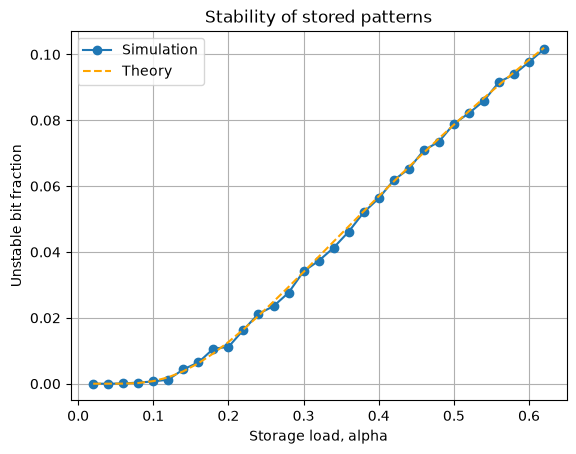

In [51]:
plt.plot(a_vals, unstable_fracs,"o-", label="Simulation")
plt.plot(a_vals,[0.5 * (1 - 1) for _ in a_vals],alpha=0)
plt.plot(a_vals, theory, '--',label='Theory',color='orange')
plt.xlabel("Storage load, alpha")
plt.ylabel("Unstable bit fraction")
plt.title("Stability of stored patterns")
plt.legend()
plt.grid(True)
plt.show()

As alpha increases, more patterns are contribuing to the crosstalk noise (ci), so a larger fraction of bits will become unstable. The simulation is very close to the theoretical values. 

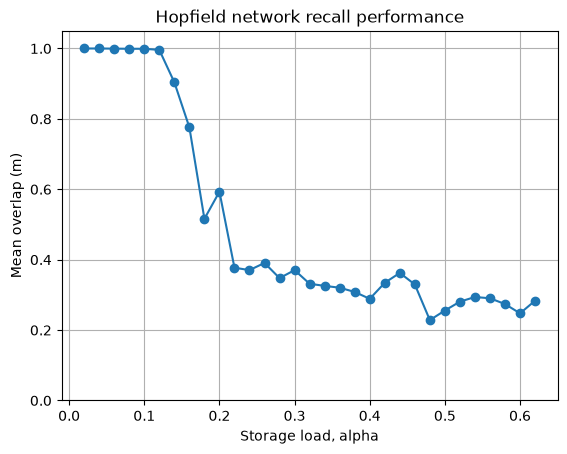

In [43]:
plt.plot(a_vals, mean_overlaps, "o-")
plt.xlabel("Storage load, alpha")
plt.ylabel("Mean overlap (m)")
plt.title("Hopfield network recall performance")
plt.ylim(0, 1.05)
plt.grid(True)
plt.show()

m=1 is perfect recall and m~ 0 is when the pattern doesn't agree with the original pattern at all. When alpha is lower, the network recovers the original patterns, but as the storage load increases recall is less reliable, so the mean overlap decreases. Recall is less reliable because of interference between patterns. 